# PIDNet-S on Cityscapes (Kaggle T4)
Epochs 484 | LR 0.01 | WD 5e-4 | Crop 1024x1024 | Batch 12 (6 x 2 gradient accumulation, mixed precision)

In [1]:
import shutil
import os

src = "/kaggle/input/datasets/ahaandesai275/model-v3/model"
dst = "/kaggle/working/model"

shutil.copytree(src, dst, dirs_exist_ok=True)

'/kaggle/working/model'

In [2]:
import os
import glob
import random
import time

import cv2
import numpy as np
from PIL import Image

import torch
import torch.backends.cudnn as cudnn
import torch.nn as nn
import torch.nn.functional as F
import torch.optim
from torch.utils import data

try:
    import yacs, tensorboardX
except ImportError:
    !pip install -q yacs tensorboardX

cv2.setNumThreads(0)  # avoid CPU oversubscription inside dataloader workers

In [3]:
from yacs.config import CfgNode as CN

_C = CN()

_C.USE_CUDA = True
_C.OUTPUT_DIR = '/kaggle/working/model'
_C.LOG_DIR = '/kaggle/working/training_log'
_C.GPUS = (0,)
_C.WORKERS = 4
_C.PRINT_FREQ = 10
_C.AUTO_RESUME = False
_C.PIN_MEMORY = True
_C.SEED = 304

# cuDNN settings
_C.CUDNN = CN()
_C.CUDNN.BENCHMARK = True
_C.CUDNN.DETERMINISTIC = False
_C.CUDNN.ENABLED = True

# Model settings (PIDNet-M)
_C.MODEL = CN()
_C.MODEL.NAME = 'pidnet_s'
_C.MODEL.PRETRAINED = '/kaggle/input/models/ahaandesai275/pidnet-sml/pytorch/default/1/PIDNet_S_ImageNet.pth.tar'
_C.MODEL.ALIGN_CORNERS = True
_C.MODEL.NUM_OUTPUTS = 2

# Loss settings
_C.LOSS = CN()
_C.LOSS.USE_OHEM = True
_C.LOSS.OHEMTHRES = 0.9
_C.LOSS.OHEMKEEP = 131072
_C.LOSS.CLASS_BALANCE = False
_C.LOSS.BALANCE_WEIGHTS = [0.4, 1.0]
_C.LOSS.SB_WEIGHTS = 1.0

# Dataset settings
_C.DATASET = CN()
_C.DATASET.DATASET = 'cityscapes'
_C.DATASET.NUM_CLASSES = 19
_C.DATASET.IMG_ROOT = '/kaggle/input/datasets/ahaandesai275/cityscapes-data/leftImg8bit_trainvaltest'
_C.DATASET.GT_ROOT = '/kaggle/input/datasets/ahaandesai275/cityscapes-data/gtFine_trainvaltest'
_C.DATASET.ROOT = '/kaggle/working'            # where the generated .lst files live
_C.DATASET.TRAIN_SET = 'list/cityscapes/train.lst'
_C.DATASET.TEST_SET = 'list/cityscapes/val.lst'

# Training settings
_C.TRAIN = CN()
_C.TRAIN.IMAGE_SIZE = [1024, 1024]  # width, height (crop)
_C.TRAIN.BASE_SIZE = 2048
_C.TRAIN.FLIP = True
_C.TRAIN.MULTI_SCALE = True
_C.TRAIN.SCALE_FACTOR = 16
_C.TRAIN.LR = 0.01
_C.TRAIN.EXTRA_LR = 0.001
_C.TRAIN.OPTIMIZER = 'sgd'
_C.TRAIN.MOMENTUM = 0.9
_C.TRAIN.WD = 0.0005
_C.TRAIN.NESTEROV = False
_C.TRAIN.IGNORE_LABEL = 255
_C.TRAIN.BEGIN_EPOCH = 0
_C.TRAIN.END_EPOCH = 484
_C.TRAIN.RESUME = True               # resumes automatically if a checkpoint is found
_C.TRAIN.BATCH_SIZE = 12             # effective batch size
_C.TRAIN.MICRO_BATCH_SIZE = 6        # per forward/backward pass on the T4; lower to 4 or 3 if you hit OOM
_C.TRAIN.AMP = True                  # fp16 mixed precision
_C.TRAIN.SHUFFLE = True
_C.TRAIN.VAL_FREQ = 5                # validate every N epochs...
_C.TRAIN.VAL_EVERY_EPOCH_LAST = 100  # ...and every epoch for the last N epochs
_C.TRAIN.TIME_LIMIT_HOURS = 11.0     # stop cleanly (with a checkpoint) before Kaggle's 12h session limit

# Testing settings
_C.TEST = CN()
_C.TEST.IMAGE_SIZE = [2048, 1024]  # width, height
_C.TEST.BASE_SIZE = 2048
_C.TEST.BATCH_SIZE_PER_GPU = 2
_C.TEST.MODEL_FILE = ''
_C.TEST.FLIP_TEST = False
_C.TEST.MULTI_SCALE = False
_C.TEST.OUTPUT_INDEX = 1

config = _C.clone()
config.freeze()

assert config.TRAIN.BATCH_SIZE % config.TRAIN.MICRO_BATCH_SIZE == 0
ACCUM_STEPS = config.TRAIN.BATCH_SIZE // config.TRAIN.MICRO_BATCH_SIZE

use_cuda = config.USE_CUDA and torch.cuda.is_available()
use_amp = use_cuda and config.TRAIN.AMP
device = torch.device('cuda' if use_cuda else 'cpu')

random.seed(config.SEED)
np.random.seed(config.SEED)
torch.manual_seed(config.SEED)
if use_cuda:
    torch.cuda.manual_seed(config.SEED)

print(f'Training device: {device} | AMP: {use_amp} | micro-batch {config.TRAIN.MICRO_BATCH_SIZE} x accum {ACCUM_STEPS} = {config.TRAIN.BATCH_SIZE}')

Training device: cuda | AMP: True | micro-batch 6 x accum 2 = 12


### Dataset lists

In [ ]:
# Build train/val .lst files from the Kaggle Cityscapes folders (input is read-only, so lists go to /kaggle/working)
def build_list(split):
    img_dir = os.path.join(config.DATASET.IMG_ROOT, 'leftImg8bit', split)
    lines = []

    for img_path in sorted(glob.glob(os.path.join(img_dir, '*', '*_leftImg8bit.png'))):
        city = os.path.basename(os.path.dirname(img_path))
        stem = os.path.basename(img_path).replace('_leftImg8bit.png', '')

        lbl_rel = f'gtFine/{split}/{city}/{stem}_gtFine_labelIds.png'
        if os.path.isfile(os.path.join(config.DATASET.GT_ROOT, lbl_rel)):
            lines.append(f'leftImg8bit/{split}/{city}/{stem}_leftImg8bit.png {lbl_rel}')

    out_path = os.path.join(config.DATASET.ROOT, f'list/cityscapes/{split}.lst')
    os.makedirs(os.path.dirname(out_path), exist_ok=True)
    with open(out_path, 'w') as f:
        f.write('\n'.join(lines) + '\n')
        
    print(f'{split}: {len(lines)} image/label pairs -> {out_path}')
    return len(lines)

n_train = build_list('train')   # expect 2975
n_val = build_list('val')       # expect 500

train: 2975 image/label pairs -> /kaggle/working/list/cityscapes/train.lst
val: 500 image/label pairs -> /kaggle/working/list/cityscapes/val.lst


### Dataset creation

In [ ]:
### Base Image Dataset, with transformations
y_k_size = 6
x_k_size = 6

class BaseDataset(data.Dataset):
    def __init__(self,
                 ignore_label=255,
                 base_size=2048,
                 crop_size=(512, 1024),
                 scale_factor=16,
                 mean=[0.485, 0.456, 0.406],
                 std=[0.229, 0.224, 0.225]):
        self.base_size = base_size
        self.crop_size = crop_size
        self.ignore_label = ignore_label
        self.mean = mean
        self.std = std
        self.scale_factor = scale_factor
        self.files = []

    def __len__(self):
        return len(self.files)

    def input_transform(self, image, city=True):
        # Normalisation using mean and stdev
        if city:
            image = image.astype(np.float32)[:, :, ::-1]
        else:
            image = image.astype(np.float32)
        image = image / 255.0
        image -= self.mean
        image /= self.std
        return image

    def label_transform(self, label):
        # Converting labels to int64
        return np.array(label).astype(np.int64)

    def pad_image(self, image, h, w, size, padvalue):
        # Adding padding to image 
        pad_image = image.copy()
        pad_h = max(size[0] - h, 0)
        pad_w = max(size[1] - w, 0)
        if pad_h > 0 or pad_w > 0:
            pad_image = cv2.copyMakeBorder(image, 0, pad_h, 0, pad_w,
                                           cv2.BORDER_CONSTANT, value=padvalue)
        return pad_image

    def rand_crop(self, image, label, edge):
        # Random cropping images 
        h, w = image.shape[:-1]
        image = self.pad_image(image, h, w, self.crop_size, (0.0, 0.0, 0.0))
        label = self.pad_image(label, h, w, self.crop_size, (self.ignore_label,))
        edge = self.pad_image(edge, h, w, self.crop_size, (0.0,))

        new_h, new_w = label.shape
        x = random.randint(0, new_w - self.crop_size[1])
        y = random.randint(0, new_h - self.crop_size[0])

        image = image[y:y+self.crop_size[0], x:x+self.crop_size[1]]
        label = label[y:y+self.crop_size[0], x:x+self.crop_size[1]]
        edge = edge[y:y+self.crop_size[0], x:x+self.crop_size[1]]

        return image, label, edge

    def multi_scale_aug(self, image, label=None, edge=None, rand_scale=1, rand_crop=True):
        # Resizes image to a random scale , and then crops optionally

        long_size = int(self.base_size * rand_scale + 0.5)

        h, w = image.shape[:2]
        if h > w:
            new_h = long_size
            new_w = int(w * long_size / h + 0.5)            # fit as per original aspect ratio
        else:
            new_w = long_size
            new_h = int(h * long_size / w + 0.5)

        # We have to resize label and edge map too 
        image = cv2.resize(image, (new_w, new_h), interpolation=cv2.INTER_LINEAR)
        if label is not None:
            label = cv2.resize(label, (new_w, new_h), interpolation=cv2.INTER_NEAREST)
            if edge is not None:
                edge = cv2.resize(edge, (new_w, new_h), interpolation=cv2.INTER_NEAREST)
        else:
            return image

        # Optional rand crop 
        if rand_crop:
            image, label, edge = self.rand_crop(image, label, edge)

        return image, label, edge

    def gen_sample(self, image, label, multi_scale=True, is_flip=True, edge_pad=True, edge_size=4, city=True):
        # Overall function that does everything

        # Edge map 
        edge_label = np.clip(label, 0, 255).astype(np.uint8)
        edge = cv2.Canny(edge_label, 0.1, 0.2)
        kernel = np.ones((edge_size, edge_size), np.uint8)
        if edge_pad:
            edge = edge[y_k_size:-y_k_size, x_k_size:-x_k_size]
            edge = np.pad(edge, ((y_k_size,y_k_size),(x_k_size,x_k_size)), mode='constant')
        edge = (cv2.dilate(edge, kernel, iterations=1)>50)*1.0

        # Multi scale augmentation
        if multi_scale:
            rand_scale = 0.5 + random.randint(0, self.scale_factor) / 10.0
            image, label, edge = self.multi_scale_aug(image, label, edge, rand_scale=rand_scale)

        # Image and label transform
        image = self.input_transform(image, city=city)
        label = self.label_transform(label)
        image = image.transpose((2, 0, 1))      # want C,H,W for a CNN
        if is_flip:
            # Random horizontal flip 
            flip = np.random.choice(2) * 2 - 1
            image = image[:, :, ::flip]
            label = label[:, ::flip]
            edge = edge[:, ::flip]
        return image, label, edge

    def inference(self, config, model, image):
        # actually running the model 
        size = image.size()
        pred = model(image)
        if config.MODEL.NUM_OUTPUTS > 1:
            pred = pred[config.TEST.OUTPUT_INDEX]
        pred = F.interpolate(input=pred, size=size[-2:], mode='bilinear', align_corners=config.MODEL.ALIGN_CORNERS)
        return pred.exp()

In [ ]:
class Cityscapes(BaseDataset):
    def __init__(self,
                 root,
                 list_path,
                 image_root,
                 gt_root,
                 num_classes=19,
                 multi_scale=True,
                 flip=True,
                 ignore_label=255,
                 base_size=2048,
                 crop_size=(512, 1024),
                 scale_factor=16,
                 mean=[0.485, 0.456, 0.406],
                 std=[0.229, 0.224, 0.225],
                 bd_dilate_size=4):

        super(Cityscapes, self).__init__(ignore_label, base_size,
                crop_size, scale_factor, mean, std,)

        self.root = root
        self.list_path = list_path
        self.image_root = image_root
        self.gt_root = gt_root
        self.num_classes = num_classes

        self.multi_scale = multi_scale
        self.flip = flip

        self.img_list = [line.strip().split() for line in open(os.path.join(root, list_path)) if line.strip()]

        self.files = self.read_files()

        # Cityscapes has 34 labels originally, we want only 19 for our model 
        self.label_mapping = {-1: ignore_label, 0: ignore_label,
                              1: ignore_label, 2: ignore_label,
                              3: ignore_label, 4: ignore_label,
                              5: ignore_label, 6: ignore_label,
                              7: 0, 8: 1, 9: ignore_label,
                              10: ignore_label, 11: 2, 12: 3,
                              13: 4, 14: ignore_label, 15: ignore_label,
                              16: ignore_label, 17: 5, 18: ignore_label,
                              19: 6, 20: 7, 21: 8, 22: 9, 23: 10, 24: 11,
                              25: 12, 26: 13, 27: 14, 28: 15,
                              29: ignore_label, 30: ignore_label,
                              31: 16, 32: 17, 33: 18}

        # Lookup table (labelId -> trainId); much faster than 34 full-image masks per sample
        self.lut = np.full(256, ignore_label, dtype=np.uint8)
        for k, v in self.label_mapping.items():
            if 0 <= k < 256:
                self.lut[k] = v

        self.class_weights = torch.FloatTensor([0.8373, 0.918, 0.866, 1.0345,
                                        1.0166, 0.9969, 0.9754, 1.0489,
                                        0.8786, 1.0023, 0.9539, 0.9843,
                                        1.1116, 0.9037, 1.0865, 1.0955,
                                        1.0865, 1.1529, 1.0507])

        self.bd_dilate_size = bd_dilate_size

        self.palette = np.array([
            [128, 64, 128], [244, 35, 232], [70, 70, 70], [102, 102, 156],
            [190, 153, 153], [153, 153, 153], [250, 170, 30], [220, 220, 0],
            [107, 142, 35], [152, 251, 152], [70, 130, 180], [220, 20, 60],
            [255, 0, 0], [0, 0, 142], [0, 0, 70], [0, 60, 100],
            [0, 80, 100], [0, 0, 230], [119, 11, 32]], dtype=np.uint8)

    def read_files(self):
        files = []
        if 'test' in self.list_path:
            for item in self.img_list:
                image_path = item
                name = os.path.splitext(os.path.basename(image_path[0]))[0]
                files.append({
                    "img": image_path[0],
                    "name": name,
                })
        else:
            for item in self.img_list:
                image_path, label_path = item
                name = os.path.splitext(os.path.basename(label_path))[0]
                files.append({
                    "img": image_path,
                    "label": label_path,
                    "name": name
                })
        return files

    def convert_label(self, label, inverse=False):
        if not inverse:
            return self.lut[label]
        
        label = label.copy()
        temp = label.copy()
        for v, k in self.label_mapping.items():
            if v >= 0 and k != self.ignore_label:
                label[temp == k] = v
        return label

    def label2color(self, label):
        color = np.zeros(label.shape + (3,), dtype=np.uint8)
        valid = label < self.num_classes
        color[valid] = self.palette[label[valid]]
        return color

    def __getitem__(self, index):
        item = self.files[index]
        name = item["name"]
        image = cv2.imread(
            os.path.join(self.image_root, item["img"]),
            cv2.IMREAD_COLOR
        )

        size = image.shape

        if 'test' in self.list_path:
            image = self.input_transform(image)
            image = image.transpose((2, 0, 1))

            return image.copy(), np.array(size), name

        label = cv2.imread(
            os.path.join(self.gt_root, item["label"]),
            cv2.IMREAD_GRAYSCALE
        )
        label = self.convert_label(label)

        image, label, edge = self.gen_sample(image, label,
                                self.multi_scale, self.flip, edge_size=self.bd_dilate_size)

        return image.copy(), label.copy(), edge.copy(), np.array(size), name

    def single_scale_inference(self, config, model, image):
        pred = self.inference(config, model, image)
        return pred

    def save_pred(self, preds, sv_path, name):
        preds = np.asarray(np.argmax(preds.cpu(), axis=1), dtype=np.uint8)
        for i in range(preds.shape[0]):
            pred = self.convert_label(preds[i], inverse=True)
            save_img = Image.fromarray(pred)
            save_img.save(os.path.join(sv_path, name[i]+'.png'))

### Model Building Blocks

In [7]:
BatchNorm2d = nn.BatchNorm2d
bn_mom = 0.1            # momentum for batch normalization
algc = False

In [8]:
# ResNet basic block - used as a skip connection
class BasicBlock(nn.Module):
    expansion = 1           # multiplier that says how many channels are produced

    def __init__(self, inplanes, planes, stride=1, downsample=None, no_relu=False):
        super(BasicBlock, self).__init__()

        # First conv layer
        self.conv1 = nn.Conv2d(inplanes, planes, kernel_size=3, stride=stride,
                               padding=1, bias=False)
        self.bn1 = BatchNorm2d(planes, momentum=bn_mom)
        self.relu = nn.ReLU(inplace=True)

        # Second conv layer 
        self.conv2 = nn.Conv2d(planes, planes, kernel_size=3,
                               padding=1, bias=False)
        self.bn2 = BatchNorm2d(planes, momentum=bn_mom)

        self.downsample = downsample
        self.stride = stride
        self.no_relu = no_relu

    def forward(self, x):
        residual = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)

        if self.downsample is not None:
            residual = self.downsample(x)

        out += residual         # model learns output + x , thus introducing a skip connection -> good for segmentation

        if self.no_relu:
            return out
        else:
            return self.relu(out)

In [ ]:
# The bottleneck layer - it is more efficient when we want depth and width without cost increase
# It squeezes the image then does processing with a higher kernel then expands it again
class Bottleneck(nn.Module):
    expansion = 2

    def __init__(self, inplanes, planes, stride=1, downsample=None, no_relu=True):
        super(Bottleneck, self).__init__()
        # First Conv layer (1x1 convolution - it computes a weighted sum of pixels across channels)
        # 1x1 conv is used to reduce dimensionality (in terms of channels) without considering spatial information
        self.conv1 = nn.Conv2d(inplanes, planes, kernel_size=1, bias=False)
        self.bn1 = BatchNorm2d(planes, momentum=bn_mom)

        # Second Conv layer with relu (3x3 convolution) - does spatial work at lower channel size
        self.conv2 = nn.Conv2d(planes, planes, kernel_size=3, stride=stride,
                               padding=1, bias=False)
        self.bn2 = BatchNorm2d(planes, momentum=bn_mom)
        self.relu = nn.ReLU(inplace=True)

        # Third conv layer with a relu (1x1 convolution)
        self.conv3 = nn.Conv2d(planes, planes * self.expansion, kernel_size=1,
                               bias=False)
        self.bn3 = BatchNorm2d(planes * self.expansion, momentum=bn_mom)


        self.downsample = downsample
        self.stride = stride
        self.no_relu = no_relu

    def forward(self, x):
        residual = x

        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)

        out = self.conv2(out)
        out = self.bn2(out)
        out = self.relu(out)

        out = self.conv3(out)
        out = self.bn3(out)

        if self.downsample is not None:
            residual = self.downsample(x)

        out += residual
        if self.no_relu:
            return out
        else:
            return self.relu(out)

In [10]:
class SegmentHead(nn.Module):

    def __init__(self, inplanes, interplanes, outplanes, scale_factor=None):
        super(SegmentHead, self).__init__()
        # Layer 1 (+ RELU)
        self.bn1 = BatchNorm2d(inplanes, momentum=bn_mom)
        self.conv1 = nn.Conv2d(inplanes, interplanes, kernel_size=3, padding=1, bias=False)

        # Layer 2 (+ RELU)
        self.bn2 = BatchNorm2d(interplanes, momentum=bn_mom)
        self.conv2 = nn.Conv2d(interplanes, outplanes, kernel_size=1, padding=0, bias=True)

        self.relu = nn.ReLU(inplace=True)

        self.scale_factor = scale_factor

    def forward(self, x):
        
        x = self.conv1(self.relu(self.bn1(x)))
        out = self.conv2(self.relu(self.bn2(x)))

        if self.scale_factor is not None:
            height = x.shape[-2] * self.scale_factor
            width = x.shape[-1] * self.scale_factor
            out = F.interpolate(out,
                        size=[height, width],
                        mode='bilinear', align_corners=algc)

        return out

##### For smaller networks, PAPPM and Light_Bag is used

In [ ]:
# Pyramid Pooling Module (PPM) - Fast Aggregation of Contexts
# This is a parallel architecture which can be used in the smaller PIDNets and is faster to train
class PAPPM(nn.Module):
    def __init__(self, inplanes, branch_planes, outplanes, BatchNorm=nn.BatchNorm2d):
        super(PAPPM, self).__init__()
        bn_mom = 0.1
        # 5x2 average pool 
        self.scale1 = nn.Sequential(nn.AvgPool2d(kernel_size=5, stride=2, padding=2),
                                    BatchNorm(inplanes, momentum=bn_mom),
                                    nn.ReLU(inplace=True),
                                    nn.Conv2d(inplanes, branch_planes, kernel_size=1, bias=False),
                                    )

        # 9x4 average pool 
        self.scale2 = nn.Sequential(nn.AvgPool2d(kernel_size=9, stride=4, padding=4),
                                    BatchNorm(inplanes, momentum=bn_mom),
                                    nn.ReLU(inplace=True),
                                    nn.Conv2d(inplanes, branch_planes, kernel_size=1, bias=False),
                                    )

        # 17x8 average pool
        self.scale3 = nn.Sequential(nn.AvgPool2d(kernel_size=17, stride=8, padding=8),
                                    BatchNorm(inplanes, momentum=bn_mom),
                                    nn.ReLU(inplace=True),
                                    nn.Conv2d(inplanes, branch_planes, kernel_size=1, bias=False),
                                    )

        # Gloabl Average Pool
        self.scale4 = nn.Sequential(nn.AdaptiveAvgPool2d((1, 1)),
                                    BatchNorm(inplanes, momentum=bn_mom),
                                    nn.ReLU(inplace=True),
                                    nn.Conv2d(inplanes, branch_planes, kernel_size=1, bias=False),
                                    )

        # 1x1 conv (skip connection)
        self.scale0 = nn.Sequential(
                                    BatchNorm(inplanes, momentum=bn_mom),
                                    nn.ReLU(inplace=True),
                                    nn.Conv2d(inplanes, branch_planes, kernel_size=1, bias=False),
                                    )

        # applies a 3x3 conv to the 4 scale outputs
        self.scale_process = nn.Sequential(
                                    BatchNorm(branch_planes*4, momentum=bn_mom),
                                    nn.ReLU(inplace=True),
                                    nn.Conv2d(branch_planes*4, branch_planes*4, kernel_size=3, padding=1, groups=4, bias=False),
                                    )

        # compresses the output to add it back to the original image 
        self.compression = nn.Sequential(
                                    BatchNorm(branch_planes * 5, momentum=bn_mom),
                                    nn.ReLU(inplace=True),
                                    nn.Conv2d(branch_planes * 5, outplanes, kernel_size=1, bias=False),
                                    )
        
        # skip connection + fit dimension via conv
        self.shortcut = nn.Sequential(
                                    BatchNorm(inplanes, momentum=bn_mom),
                                    nn.ReLU(inplace=True),
                                    nn.Conv2d(inplanes, outplanes, kernel_size=1, bias=False),
                                    )


    def forward(self, x):
        width = x.shape[-1]
        height = x.shape[-2]        
        scale_list = []

        x_ = self.scale0(x)
        scale_list.append(F.interpolate(self.scale1(x), size=[height, width],
                        mode='bilinear', align_corners=algc)+x_)
        scale_list.append(F.interpolate(self.scale2(x), size=[height, width],
                        mode='bilinear', align_corners=algc)+x_)
        scale_list.append(F.interpolate(self.scale3(x), size=[height, width],
                        mode='bilinear', align_corners=algc)+x_)
        scale_list.append(F.interpolate(self.scale4(x), size=[height, width],
                        mode='bilinear', align_corners=algc)+x_)
        
        scale_out = self.scale_process(torch.cat(scale_list, 1))
       
        out = self.compression(torch.cat([x_,scale_out], 1)) + self.shortcut(x)
        return out

In [ ]:
# Combination of p,i,d barnches 
class Light_Bag(nn.Module):
    def __init__(self, in_channels, out_channels, BatchNorm=nn.BatchNorm2d):
        super(Light_Bag, self).__init__()
        self.conv_p = nn.Sequential(
                                nn.Conv2d(in_channels, out_channels, 
                                          kernel_size=1, bias=False),
                                BatchNorm(out_channels)
                                )
        self.conv_i = nn.Sequential(
                                nn.Conv2d(in_channels, out_channels, 
                                          kernel_size=1, bias=False),
                                BatchNorm(out_channels)
                                )
        
    def forward(self, p, i, d):
        edge_att = torch.sigmoid(d)         # squashes output to between 0-1 , 0 being flat region , 1 being boundary
        
        p_add = self.conv_p((1-edge_att)*i + p) # if its not near an edge we prefer I branch as it is semantically rich
        i_add = self.conv_i(i + edge_att*p) # if it is then we want P branch which is good at high resolution detail
        
        return p_add + i_add  # exact mixing is learnt, hence convolution on the P and I parts 
    

In [ ]:
# This is for learning high level semantics selectively 
# Takes in input from I channel to supply to P channel 

class PagFM(nn.Module):
    def __init__(self, in_channels, mid_channels, after_relu=False, with_channel=False, BatchNorm=nn.BatchNorm2d):
        super(PagFM, self).__init__()
        self.with_channel = with_channel
        self.after_relu = after_relu
        self.f_x = nn.Sequential(
                                nn.Conv2d(in_channels, mid_channels, 
                                          kernel_size=1, bias=False),
                                BatchNorm(mid_channels)
                                )
        self.f_y = nn.Sequential(
                                nn.Conv2d(in_channels, mid_channels, 
                                          kernel_size=1, bias=False),
                                BatchNorm(mid_channels)
                                )
        if with_channel:
            self.up = nn.Sequential(
                                    nn.Conv2d(mid_channels, in_channels, 
                                              kernel_size=1, bias=False),
                                    BatchNorm(in_channels)
                                   )
        if after_relu:
            self.relu = nn.ReLU(inplace=True)
        
    def forward(self, x, y):
        input_size = x.size()
        if self.after_relu:
            y = self.relu(y)
            x = self.relu(x)

        y_q = self.f_y(y)
        y_q = F.interpolate(y_q, size=[input_size[2], input_size[3]],
                            mode='bilinear', align_corners=False)
        x_k = self.f_x(x)
        
        if self.with_channel:
            sim_map = torch.sigmoid(self.up(x_k * y_q))
        else:
            sim_map = torch.sigmoid(torch.sum(x_k * y_q, dim=1).unsqueeze(1))
        
        y = F.interpolate(y, size=[input_size[2], input_size[3]],
                            mode='bilinear', align_corners=False)
        x = (1-sim_map)*x + sim_map*y
        
        return x

### Combined Network

In [ ]:
class PIDNet(nn.Module):
    def __init__(self, m=2, n=3, num_classes=19, planes=64, ppm_planes=96, head_planes=128, augment=True):
        super(PIDNet, self).__init__()
        self.augment = augment

                
        # I Branch - Central Branch 
        self.conv1 =  nn.Sequential(
                          nn.Conv2d(3,planes,kernel_size=3, stride=2, padding=1),       
                          BatchNorm2d(planes, momentum=bn_mom),
                          nn.ReLU(inplace=True), 

                          nn.Conv2d(planes,planes,kernel_size=3, stride=2, padding=1),
                          BatchNorm2d(planes, momentum=bn_mom),
                          nn.ReLU(inplace=True),
                      )
        
        self.relu = nn.ReLU(inplace=True)
        self.layer1 = self._make_layer(BasicBlock, planes, planes, m)
        self.layer2 = self._make_layer(BasicBlock, planes, planes * 2, m, stride=2)
        self.layer3 = self._make_layer(BasicBlock, planes * 2, planes * 4, n, stride=2)
        self.layer4 = self._make_layer(BasicBlock, planes * 4, planes * 8, n, stride=2)
        self.layer5 =  self._make_layer(Bottleneck, planes * 8, planes * 8, 2, stride=2)

        
        # P Branch
        self.compression3 = nn.Sequential(
                                nn.Conv2d(planes * 4, planes * 2, kernel_size=1, bias=False),
                                BatchNorm2d(planes * 2, momentum=bn_mom),
                            )

        self.compression4 = nn.Sequential(
                                nn.Conv2d(planes * 8, planes * 2, kernel_size=1, bias=False),
                                BatchNorm2d(planes * 2, momentum=bn_mom),
                            )
        
        self.pag3 = PagFM(planes * 2, planes)
        self.pag4 = PagFM(planes * 2, planes)

        self.layer3_p = self._make_layer(BasicBlock, planes * 2, planes * 2, m)
        self.layer4_p = self._make_layer(BasicBlock, planes * 2, planes * 2, m)
        self.layer5_p = self._make_layer(Bottleneck, planes * 2, planes * 2, 1)        
        
        # D Branch
        # Considering only PID-S and PID-M for now
        self.layer3_d = self._make_single_layer(BasicBlock, planes * 2, planes)
        self.layer4_d = self._make_layer(Bottleneck, planes, planes, 1)
        self.diff3 = nn.Sequential(
                                    nn.Conv2d(planes * 4, planes, kernel_size=3, padding=1, bias=False),
                                    BatchNorm2d(planes, momentum=bn_mom),
                                    )
        self.diff4 = nn.Sequential(
                                    nn.Conv2d(planes * 8, planes * 2, kernel_size=3, padding=1, bias=False),
                                    BatchNorm2d(planes * 2, momentum=bn_mom),
                                    )
        self.ppm = PAPPM(planes * 16, ppm_planes, planes * 4)
        self.dfm = Light_Bag(planes * 4, planes * 4)


        self.layer5_d = self._make_layer(Bottleneck, planes * 2, planes * 2, 1)
        
        # Prediction Head
        if self.augment:
            self.seghead_p = SegmentHead(planes * 2, head_planes, num_classes)
            self.seghead_d = SegmentHead(planes * 2, planes, 1)           

        self.final_layer = SegmentHead(planes * 4, head_planes, num_classes)


        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, BatchNorm2d):
                nn.init.constant_(m.weight, 1)
                nn.init.constant_(m.bias, 0)


    def _make_layer(self, block, inplanes, planes, blocks, stride=1):
        # Adds multiple layers of Basic blocks or BottleNecks

        downsample = None
        if stride != 1 or inplanes != planes * block.expansion:
            # add a downsampling layer if the conditions require it 

            downsample = nn.Sequential(
                nn.Conv2d(inplanes, planes * block.expansion,
                          kernel_size=1, stride=stride, bias=False),

                nn.BatchNorm2d(planes * block.expansion, momentum=bn_mom),
            )

        layers = []
        layers.append(block(inplanes, planes, stride, downsample))      # want downsampling in the very first layer 
        inplanes = planes * block.expansion     

        for i in range(1, blocks):
            # Build blocks and add
            if i == (blocks-1):
                # We do not want relu for the last layer 
                layers.append(block(inplanes, planes, stride=1, no_relu=True))
            else:
                layers.append(block(inplanes, planes, stride=1, no_relu=False))

        return nn.Sequential(*layers)
    
    def _make_single_layer(self, block, inplanes, planes, stride=1):
        # Just one layer of BasicBlock or Bottleneck
        downsample = None
        if stride != 1 or inplanes != planes * block.expansion:
            downsample = nn.Sequential(
                nn.Conv2d(inplanes, planes * block.expansion,
                          kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(planes * block.expansion, momentum=bn_mom),
            )

        layer = block(inplanes, planes, stride, downsample, no_relu=True)
        
        return layer

    def forward(self, x):

        width_output = x.shape[-1] // 8
        height_output = x.shape[-2] // 8

        # First few blocks (Stage 0,1)
        x = self.conv1(x)
        x = self.relu(self.layer1(x))
        x = self.relu(self.layer2(x))

        ## Stage 2 & 3

        # At this stage it will branch to P & D branches , x will continue to I branch (Stage 2)
        # Stage 3 consists of another convolution layer + Pag3 and Add blocks in P & D branches resp.
        x_p = self.layer3_p(x)      
        x_d = self.layer3_d(x)
        x = self.relu(self.layer3(x))

        # The Pag3 block in P branch  takes input from I branch 
        x_p = self.pag3(x_p, self.compression3(x))

        # The addition (Add) block in D branch takes input from I branch
        x_d = x_d + F.interpolate(
            self.diff3(x),
            size=[height_output, width_output],
            mode="bilinear",
            align_corners=algc,
        )

        if self.augment:
            temp_p = x_p

        ## Stage 4 - Another conv + Pag + Add
        x = self.relu(self.layer4(x))
        x_p = self.layer4_p(self.relu(x_p))
        x_d = self.layer4_d(self.relu(x_d))
 
        x_p = self.pag4(x_p, self.compression4(x))

        x_d = x_d + F.interpolate(
            self.diff4(x),
            size=[height_output, width_output],
            mode="bilinear",
            align_corners=algc,
        )

        if self.augment:
            temp_d = x_d

        # Stage 5 (Only Conv layers )
        x_p = self.layer5_p(self.relu(x_p))
        x_d = self.layer5_d(self.relu(x_d))
        x = self.layer5(x)

        # Stage 6 
        # a. Applying PPM layer to x
        # and resizing
        x = F.interpolate(
            self.ppm(x),
            size=[height_output, width_output],
            mode="bilinear",
            align_corners=algc,
        )

        # Applying Final S-HEAD after bagging (dfm)
        x_ = self.final_layer(self.dfm(x_p, x, x_d))

        if self.augment:
            x_extra_p = self.seghead_p(temp_p)
            x_extra_d = self.seghead_d(temp_d)
            return [x_extra_p, x_, x_extra_d]

        return x_

In [15]:
# Model with loss function
class FullModel(nn.Module):

  def __init__(self, model, sem_loss, bd_loss):
    super(FullModel, self).__init__()
    self.model = model
    self.sem_loss = sem_loss
    self.bd_loss = bd_loss

  def pixel_acc(self, pred, label):
    _, preds = torch.max(pred, dim=1)
    valid = (label != config.TRAIN.IGNORE_LABEL).long()
    acc_sum = torch.sum(valid * (preds == label).long())
    pixel_sum = torch.sum(valid)
    acc = acc_sum.float() / (pixel_sum.float() + 1e-10)
    return acc

  def forward(self, inputs, labels, bd_gt, *args, **kwargs):
    
    outputs = self.model(inputs, *args, **kwargs)
    
    h, w = labels.size(1), labels.size(2)
    ph, pw = outputs[0].size(2), outputs[0].size(3)
    if ph != h or pw != w:
        for i in range(len(outputs)):
            outputs[i] = F.interpolate(outputs[i], size=(
                h, w), mode='bilinear', align_corners=config.MODEL.ALIGN_CORNERS)

    acc  = self.pixel_acc(outputs[-2], labels)
    loss_s = self.sem_loss(outputs[:-1], labels)
    loss_b = self.bd_loss(outputs[-1], bd_gt)

    filler = torch.ones_like(labels) * config.TRAIN.IGNORE_LABEL
    bd_label = torch.where(F.sigmoid(outputs[-1][:,0,:,:])>0.8, labels, filler)
    loss_sb = self.sem_loss([outputs[-2]], bd_label)
    loss = loss_s + loss_b + loss_sb

    return torch.unsqueeze(loss,0), outputs[:-1], acc, [loss_s, loss_b]

In [16]:
# Use the underlying PIDNet for inference, not the training loss wrapper.
def inference_model(config, model, image):
    if isinstance(model, nn.DataParallel):
        model = model.module
    if isinstance(model, FullModel):
        model = model.model

    model.eval()
    with torch.no_grad():
        pred = model(image)

    if config.MODEL.NUM_OUTPUTS > 1:
        pred = pred[config.TEST.OUTPUT_INDEX]

    return F.interpolate(
        input=pred,
        size=image.shape[-2:],
        mode='bilinear',
        align_corners=config.MODEL.ALIGN_CORNERS
    ).exp()

BaseDataset.inference = inference_model

### Model Training

##### Device, model and dataloaders

In [17]:
cudnn.benchmark = use_cuda and config.CUDNN.BENCHMARK
cudnn.deterministic = config.CUDNN.DETERMINISTIC
cudnn.enabled = use_cuda and config.CUDNN.ENABLED
gpus = list(config.GPUS) if use_cuda else []

if use_cuda:
    print(f'CUDA device count: {torch.cuda.device_count()} | {torch.cuda.get_device_name(0)}')
    if torch.cuda.device_count() < len(gpus):
        raise RuntimeError(f'Requested GPUs {gpus}, but only {torch.cuda.device_count()} are available.')
else:
    print('Running on CPU')
!nvidia-smi

CUDA device count: 2 | Tesla T4
Tue Nov 10 05:16:40 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   51C    P8             11W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+---------------

In [ ]:
# PIDNet-S with ImageNet-pretrained weights
def get_seg_model(cfg, imgnet_pretrained):
    if 's' in cfg.MODEL.NAME:
        model = PIDNet(
            m=2, n=3, num_classes=cfg.DATASET.NUM_CLASSES,
            planes=32, ppm_planes=96, head_planes=128, augment=True
        )
    elif 'm' in cfg.MODEL.NAME:
        model = PIDNet(
            m=2, n=3, num_classes=cfg.DATASET.NUM_CLASSES,
            planes=64, ppm_planes=96, head_planes=128, augment=True
        )
    else:
        # PIDNET L 
        model = PIDNet(
            m=3, n=4, num_classes=cfg.DATASET.NUM_CLASSES,
            planes=64, ppm_planes=112, head_planes=256, augment=True
        )

    pretrained_path = cfg.MODEL.PRETRAINED
    if not os.path.isfile(pretrained_path):
        print(f'Pretrained weights not found at {pretrained_path}; using random initialization.')
        return model

    pretrained_checkpoint = torch.load(pretrained_path, map_location='cpu', weights_only=False)
    pretrained_state = pretrained_checkpoint.get('state_dict', pretrained_checkpoint)
    model_dict = model.state_dict()

    if imgnet_pretrained:
        compatible_state = {
            k: v for k, v in pretrained_state.items()
            if k in model_dict and v.shape == model_dict[k].shape
        }
    else:
        compatible_state = {
            k[6:]: v for k, v in pretrained_state.items()
            if k.startswith('module.') and k[6:] in model_dict
            and v.shape == model_dict[k[6:]].shape
        }

    model_dict.update(compatible_state)
    model.load_state_dict(model_dict, strict=False)
    print(f'Loaded {len(compatible_state)} compatible pretrained tensors from {pretrained_path}')
    return model


imgnet = 'imagenet' in config.MODEL.PRETRAINED.lower()
model = get_seg_model(config, imgnet_pretrained=imgnet)

Loaded 230 compatible pretrained tensors from /kaggle/input/models/ahaandesai275/pidnet-sml/pytorch/default/1/PIDNet_S_ImageNet.pth.tar


In [19]:
# Train dataset and loader
crop_size = (config.TRAIN.IMAGE_SIZE[1], config.TRAIN.IMAGE_SIZE[0])
train_dataset = Cityscapes(
    root=config.DATASET.ROOT,
    list_path=config.DATASET.TRAIN_SET,
    image_root=config.DATASET.IMG_ROOT,
    gt_root=config.DATASET.GT_ROOT,
    num_classes=config.DATASET.NUM_CLASSES,
    multi_scale=config.TRAIN.MULTI_SCALE,
    flip=config.TRAIN.FLIP,
    ignore_label=config.TRAIN.IGNORE_LABEL,
    base_size=config.TRAIN.BASE_SIZE,
    crop_size=crop_size,
    scale_factor=config.TRAIN.SCALE_FACTOR
)

train_workers = config.WORKERS if use_cuda else 0
trainloader = torch.utils.data.DataLoader(
    train_dataset,
    batch_size=config.TRAIN.MICRO_BATCH_SIZE,
    shuffle=config.TRAIN.SHUFFLE,
    num_workers=train_workers,
    pin_memory=use_cuda and config.PIN_MEMORY,
    drop_last=True,
    persistent_workers=train_workers > 0,
)
print(f'Train samples: {len(train_dataset)}, micro-batch size: {config.TRAIN.MICRO_BATCH_SIZE}')

Train samples: 2975, micro-batch size: 6


In [20]:
# Validation dataset and loader (full 1024x2048 images)
test_size = (config.TEST.IMAGE_SIZE[1], config.TEST.IMAGE_SIZE[0])
test_dataset = Cityscapes(
    root=config.DATASET.ROOT,
    list_path=config.DATASET.TEST_SET,
    image_root=config.DATASET.IMG_ROOT,
    gt_root=config.DATASET.GT_ROOT,
    num_classes=config.DATASET.NUM_CLASSES,
    multi_scale=False,
    flip=False,
    ignore_label=config.TRAIN.IGNORE_LABEL,
    base_size=config.TEST.BASE_SIZE,
    crop_size=test_size
)

testloader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=config.TEST.BATCH_SIZE_PER_GPU,
    shuffle=False,
    num_workers=train_workers,
    pin_memory=use_cuda and config.PIN_MEMORY,
    persistent_workers=train_workers > 0,
)
print(f'Validation samples: {len(test_dataset)}, batch size: {config.TEST.BATCH_SIZE_PER_GPU}')

Validation samples: 500, batch size: 2


#### Loss function and Optimizer

In [ ]:
def weighted_bce(pred, target):
    pred = pred.float().reshape(-1)
    target = target.reshape(-1).to(dtype=pred.dtype)
    pos_mask = target == 1
    neg_mask = target == 0
    pos_count = pos_mask.sum()
    neg_count = neg_mask.sum()
    total_count = pos_count + neg_count
    weights = torch.zeros_like(target, dtype=pred.dtype)
    if total_count > 0:
        weights[pos_mask] = neg_count.float() / total_count.float()
        weights[neg_mask] = pos_count.float() / total_count.float()
    return F.binary_cross_entropy_with_logits(
        pred, target, weight=weights, reduction='mean'
    )

class CrossEntropy(nn.Module):
    def __init__(self, ignore_label=-1, weight=None):
        super(CrossEntropy, self).__init__()
        self.ignore_label = ignore_label
        self.criterion = nn.CrossEntropyLoss(
            weight=weight,
            ignore_index=ignore_label
        )

    def _forward(self, score, target):
        return self.criterion(score, target)

    def forward(self, score, target):
        if config.MODEL.NUM_OUTPUTS == 1:
            score = [score]

        balance_weights = config.LOSS.BALANCE_WEIGHTS
        sb_weights = config.LOSS.SB_WEIGHTS
        if len(balance_weights) == len(score):
            return sum([w * self._forward(x, target) for (w, x) in zip(balance_weights, score)])
        if len(score) == 1:
            return sb_weights * self._forward(score[0], target)
        raise ValueError('lengths of prediction and target are not identical!')


class OhemCrossEntropy(nn.Module):
    # Online hard example mining: used by PIDNet on Cityscapes (LOSS.USE_OHEM = True)
    def __init__(self, ignore_label=-1, thres=0.7, min_kept=100000, weight=None):
        super(OhemCrossEntropy, self).__init__()
        self.thresh = thres
        self.min_kept = max(1, min_kept)
        self.ignore_label = ignore_label
        self.criterion = nn.CrossEntropyLoss(
            weight=weight,
            ignore_index=ignore_label,
            reduction='none'
        )

    def _resize(self, score, target):
        ph, pw = score.size(2), score.size(3)
        h, w = target.size(1), target.size(2)
        if ph != h or pw != w:
            score = F.interpolate(input=score, size=(h, w), mode='bilinear',
                                  align_corners=config.MODEL.ALIGN_CORNERS)
        return score

    def _ce_forward(self, score, target):
        score = self._resize(score, target)
        return self.criterion(score, target).mean()

    def _ohem_forward(self, score, target, **kwargs):
        score = self._resize(score, target)
        pred = F.softmax(score, dim=1)
        pixel_losses = self.criterion(score, target).contiguous().view(-1)
        mask = target.contiguous().view(-1) != self.ignore_label

        tmp_target = target.clone()
        tmp_target[tmp_target == self.ignore_label] = 0
        pred = pred.gather(1, tmp_target.unsqueeze(1))
        pred, ind = pred.contiguous().view(-1,)[mask].contiguous().sort()
        if pred.numel() == 0:
            return score.sum() * 0.0
        min_value = pred[min(self.min_kept, pred.numel() - 1)]
        threshold = max(min_value, self.thresh)

        pixel_losses = pixel_losses[mask][ind]
        pixel_losses = pixel_losses[pred < threshold]
        return pixel_losses.mean()

    def forward(self, score, target):
        if config.MODEL.NUM_OUTPUTS == 1:
            score = [score]

        balance_weights = config.LOSS.BALANCE_WEIGHTS
        sb_weights = config.LOSS.SB_WEIGHTS
        if len(balance_weights) == len(score):
            functions = [self._ce_forward] * (len(balance_weights) - 1) + [self._ohem_forward]
            return sum([w * func(x, target) for (w, x, func) in zip(balance_weights, score, functions)])
        if len(score) == 1:
            return sb_weights * self._ohem_forward(score[0], target)
        raise ValueError('lengths of prediction and target are not identical!')


class BoundaryLoss(nn.Module):
    def __init__(self, coeff_bce=20.0):
        super(BoundaryLoss, self).__init__()
        self.coeff_bce = coeff_bce

    def forward(self, bd_pre, bd_gt):
        return self.coeff_bce * weighted_bce(bd_pre, bd_gt)

class_weights = train_dataset.class_weights.to(device)
if config.LOSS.USE_OHEM:
    sem_criterion = OhemCrossEntropy(
        ignore_label=config.TRAIN.IGNORE_LABEL,
        thres=config.LOSS.OHEMTHRES,
        min_kept=config.LOSS.OHEMKEEP,
        weight=class_weights
    )
else:
    sem_criterion = CrossEntropy(
        ignore_label=config.TRAIN.IGNORE_LABEL,
        weight=class_weights
    )
bd_criterion = BoundaryLoss()

model = FullModel(model, sem_criterion, bd_criterion).to(device)
if use_cuda and len(gpus) > 1:
    model = nn.DataParallel(model, device_ids=gpus)

params = [{'params': list(model.parameters()), 'lr': config.TRAIN.LR}]
optimizer = torch.optim.SGD(
    params,
    lr=config.TRAIN.LR,
    momentum=config.TRAIN.MOMENTUM,
    weight_decay=config.TRAIN.WD,
    nesterov=config.TRAIN.NESTEROV,
)
scaler = torch.amp.GradScaler('cuda', enabled=use_amp)

#### Training Loop

In [22]:
def adjust_learning_rate(optimizer, base_lr, max_iters, cur_iters, power=0.9, nbb_mult=10):
    lr = base_lr * ((1 - float(cur_iters) / max_iters) ** power)
    optimizer.param_groups[0]['lr'] = lr
    if len(optimizer.param_groups) == 2:
        optimizer.param_groups[1]['lr'] = lr * nbb_mult
    return lr


def get_confusion_matrix(label, pred, num_class, ignore=255):
    # Computed on the GPU: argmax + bincount, only a num_class x num_class matrix goes to the CPU
    seg_pred = pred.argmax(dim=1)
    valid = (label != ignore) & (label >= 0) & (label < num_class)
    index = label[valid] * num_class + seg_pred[valid]
    cm = torch.bincount(index, minlength=num_class * num_class)
    return cm.reshape(num_class, num_class).cpu().numpy().astype(np.float64)


def train(config, epoch, num_epoch, epoch_iters, base_lr,
          num_iters, trainloader, optimizer, model, scaler, writer_dict):
    model.train()
    total_loss = 0.0
    total_acc = 0.0
    total_sem_loss = 0.0
    total_bce_loss = 0.0
    total_samples = 0

    cur_iters = epoch * epoch_iters
    writer = writer_dict['writer']
    global_steps = writer_dict['train_global_steps']

    optimizer.zero_grad(set_to_none=True)
    opt_step = 0
    for i_iter, batch in enumerate(trainloader):
        if i_iter >= epoch_iters * ACCUM_STEPS:
            break
        images, labels, bd_gts, _, _ = batch
        images = images.to(device, non_blocking=use_cuda)
        labels = labels.long().to(device, non_blocking=use_cuda)
        bd_gts = bd_gts.float().to(device, non_blocking=use_cuda)

        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
            losses, _, acc, loss_list = model(images, labels, bd_gts)
            loss = losses.mean()
        acc = acc.mean()

        scaler.scale(loss / ACCUM_STEPS).backward()

        if (i_iter + 1) % ACCUM_STEPS == 0:
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            opt_step += 1
            adjust_learning_rate(optimizer, base_lr, num_iters, opt_step + cur_iters)

        batch_size = images.size(0)
        total_samples += batch_size
        total_loss += loss.item() * batch_size
        total_acc += acc.item() * batch_size
        total_sem_loss += loss_list[0].mean().item() * batch_size
        total_bce_loss += loss_list[1].mean().item() * batch_size

    avg_loss = total_loss / total_samples
    avg_acc = total_acc / total_samples
    avg_sem = total_sem_loss / total_samples
    avg_bce = total_bce_loss / total_samples
    avg_sb = avg_loss - avg_sem - avg_bce
    lrs = [x['lr'] for x in optimizer.param_groups]

    print(
        f'Epoch {epoch + 1}/{num_epoch} complete | lr: {lrs}, '
        f'Loss: {avg_loss:.6f}, Acc: {avg_acc:.6f}, '
        f'Semantic: {avg_sem:.6f}, BCE: {avg_bce:.6f}, SB: {avg_sb:.6f}'
    )
    writer.add_scalar('train_loss', avg_loss, global_steps)
    writer_dict['train_global_steps'] = global_steps + 1


def validate(config, testloader, model, writer_dict):
    model.eval()
    total_loss = 0.0
    total_samples = 0
    nums = config.MODEL.NUM_OUTPUTS
    ncls = config.DATASET.NUM_CLASSES
    confusion_matrix = np.zeros((ncls, ncls, nums))

    with torch.no_grad():
        for batch in testloader:
            image, label, bd_gts, _, _ = batch
            size = label.size()
            image = image.to(device, non_blocking=use_cuda)
            label = label.long().to(device, non_blocking=use_cuda)
            bd_gts = bd_gts.float().to(device, non_blocking=use_cuda)

            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
                losses, pred, _, _ = model(image, label, bd_gts)
            if not isinstance(pred, (list, tuple)):
                pred = [pred]

            for i, x in enumerate(pred):
                if x.shape[-2:] != size[-2:]:
                    x = F.interpolate(
                        input=x, size=size[-2:], mode='bilinear',
                        align_corners=config.MODEL.ALIGN_CORNERS
                    )
                confusion_matrix[..., i] += get_confusion_matrix(
                    label, x, ncls, config.TRAIN.IGNORE_LABEL
                )

            loss = losses.mean()
            batch_size = image.size(0)
            total_loss += loss.item() * batch_size
            total_samples += batch_size

    for i in range(nums):
        pos = confusion_matrix[..., i].sum(1)
        res = confusion_matrix[..., i].sum(0)
        tp = np.diag(confusion_matrix[..., i])
        IoU_array = tp / np.maximum(1.0, pos + res - tp)
        mean_IoU = IoU_array.mean()
        print(f'Output {i} | Mean IoU: {mean_IoU:.4f}')

    print('IoU per class (final output):')
    print(np.round(IoU_array, 4))

    avg_loss = total_loss / total_samples
    writer = writer_dict['writer']
    global_steps = writer_dict['valid_global_steps']
    writer.add_scalar('valid_loss', avg_loss, global_steps)
    writer.add_scalar('valid_mIoU', mean_IoU, global_steps)
    writer_dict['valid_global_steps'] = global_steps + 1

    return avg_loss, mean_IoU, IoU_array

In [23]:
from tensorboardX import SummaryWriter
import timeit

os.makedirs(config.OUTPUT_DIR, exist_ok=True)
epoch_iters = max(1, len(train_dataset) // config.TRAIN.BATCH_SIZE)   # optimizer steps per epoch (247 for 2975 images)
final_output_dir = config.OUTPUT_DIR
tb_log_dir = config.LOG_DIR

writer_dict = {
    'writer': SummaryWriter(tb_log_dir),
    'train_global_steps': 0,
    'valid_global_steps': 0,
}

best_mIoU = 0.0
last_epoch = config.TRAIN.BEGIN_EPOCH


def unwrap_model(model):
    return model.module if isinstance(model, nn.DataParallel) else model


def find_checkpoint():
    # Current session output first, then a previous session's output attached as a Kaggle input
    candidates = [os.path.join(final_output_dir, 'checkpoint.pth.tar')]
    for depth in range(1, 6):
        candidates += sorted(glob.glob('/kaggle/input/' + '*/' * (depth - 1) + 'checkpoint.pth.tar'))
        candidates += sorted(glob.glob('/kaggle/input/' + '*/' * (depth - 1) + 'model/checkpoint.pth.tar'))
    for path in candidates:
        if os.path.isfile(path):
            return path
    return None


if config.TRAIN.RESUME:
    model_state_file = find_checkpoint() 
    if model_state_file is not None:
        checkpoint = torch.load(model_state_file, map_location=device, weights_only=False)
        best_mIoU = checkpoint['best_mIoU']
        last_epoch = checkpoint['epoch']
        unwrap_model(model).load_state_dict(checkpoint['state_dict'])
        optimizer.load_state_dict(checkpoint['optimizer'])
        if 'scaler' in checkpoint and use_amp:
            scaler.load_state_dict(checkpoint['scaler'])
        print(f"=> Resumed from {model_state_file} (epoch {checkpoint['epoch']}, best mIoU {best_mIoU:.4f})")
    else:
        print('=> No checkpoint found, starting from scratch')

start = timeit.default_timer()
end_epoch = config.TRAIN.END_EPOCH
num_iters = end_epoch * epoch_iters
time_limit = config.TRAIN.TIME_LIMIT_HOURS * 3600
max_cycle = 0.0

for epoch in range(last_epoch, end_epoch):
    cycle_start = timeit.default_timer()

    train(
        config, epoch, end_epoch, epoch_iters, config.TRAIN.LR,
        num_iters, trainloader, optimizer, model, scaler, writer_dict
    )

    # Stop cleanly if another epoch would not fit in the session
    elapsed = timeit.default_timer() - start
    out_of_time = elapsed + 1.5 * max(max_cycle, timeit.default_timer() - cycle_start) > time_limit
    last_n = epoch >= end_epoch - config.TRAIN.VAL_EVERY_EPOCH_LAST
    do_val = (epoch % config.TRAIN.VAL_FREQ == 0) or last_n or out_of_time or epoch == end_epoch - 1

    if do_val:
        valid_loss, mean_IoU, IoU_array = validate(config, testloader, model, writer_dict)
        if mean_IoU > best_mIoU:
            best_mIoU = mean_IoU
            torch.save(unwrap_model(model).state_dict(), os.path.join(final_output_dir, 'best.pt'))
        print(f'Val Loss: {valid_loss:.3f}, MeanIU: {mean_IoU:4.4f}, Best_mIoU: {best_mIoU:4.4f}')

    checkpoint_path = os.path.join(final_output_dir, 'checkpoint.pth.tar')
    torch.save({
        'epoch': epoch + 1,
        'best_mIoU': best_mIoU,
        'state_dict': unwrap_model(model).state_dict(),
        'optimizer': optimizer.state_dict(),
        'scaler': scaler.state_dict(),
    }, checkpoint_path + '.tmp')
    os.replace(checkpoint_path + '.tmp', checkpoint_path)

    max_cycle = max(max_cycle, timeit.default_timer() - cycle_start)
    print(f'Epoch time: {timeit.default_timer() - cycle_start:.0f}s | total elapsed: {(timeit.default_timer() - start) / 3600:.2f}h')

    if out_of_time and epoch + 1 < end_epoch:
        print(f'Time limit reached after epoch {epoch + 1}. Checkpoint saved; start a new session and resume.')
        break

if epoch + 1 >= end_epoch:
    torch.save(unwrap_model(model).state_dict(), os.path.join(final_output_dir, 'final_state.pt'))
writer_dict['writer'].close()
end = timeit.default_timer()
print(f'Hours: {(end - start) / 3600:.2f}')
print('Done')

=> Resumed from /kaggle/working/model/checkpoint.pth.tar (epoch 340, best mIoU 0.7501)
Epoch 341/484 complete | lr: [0.0033376562669322042], Loss: 1.791742, Acc: 0.963780, Semantic: 0.712016, BCE: 0.399196, SB: 0.680530
Output 0 | Mean IoU: 0.4823
Output 1 | Mean IoU: 0.7501
IoU per class (final output):
[0.9773 0.8251 0.9187 0.5149 0.5926 0.6205 0.6855 0.7507 0.9169 0.6298
 0.9443 0.7984 0.5887 0.9378 0.7317 0.7779 0.6934 0.5899 0.7585]
Val Loss: 1.999, MeanIU: 0.7501, Best_mIoU: 0.7501
Epoch time: 492s | total elapsed: 0.14h
Epoch 342/484 complete | lr: [0.0033166426749413782], Loss: 1.810203, Acc: 0.963017, Semantic: 0.720300, BCE: 0.407670, SB: 0.682234
Epoch time: 318s | total elapsed: 0.22h
Epoch 343/484 complete | lr: [0.0032956142793059136], Loss: 1.823550, Acc: 0.961613, Semantic: 0.724244, BCE: 0.410890, SB: 0.688416
Epoch time: 317s | total elapsed: 0.31h
Epoch 344/484 complete | lr: [0.0032745709644934912], Loss: 1.815590, Acc: 0.962995, Semantic: 0.725095, BCE: 0.402820, S

#### Visualize a validation prediction

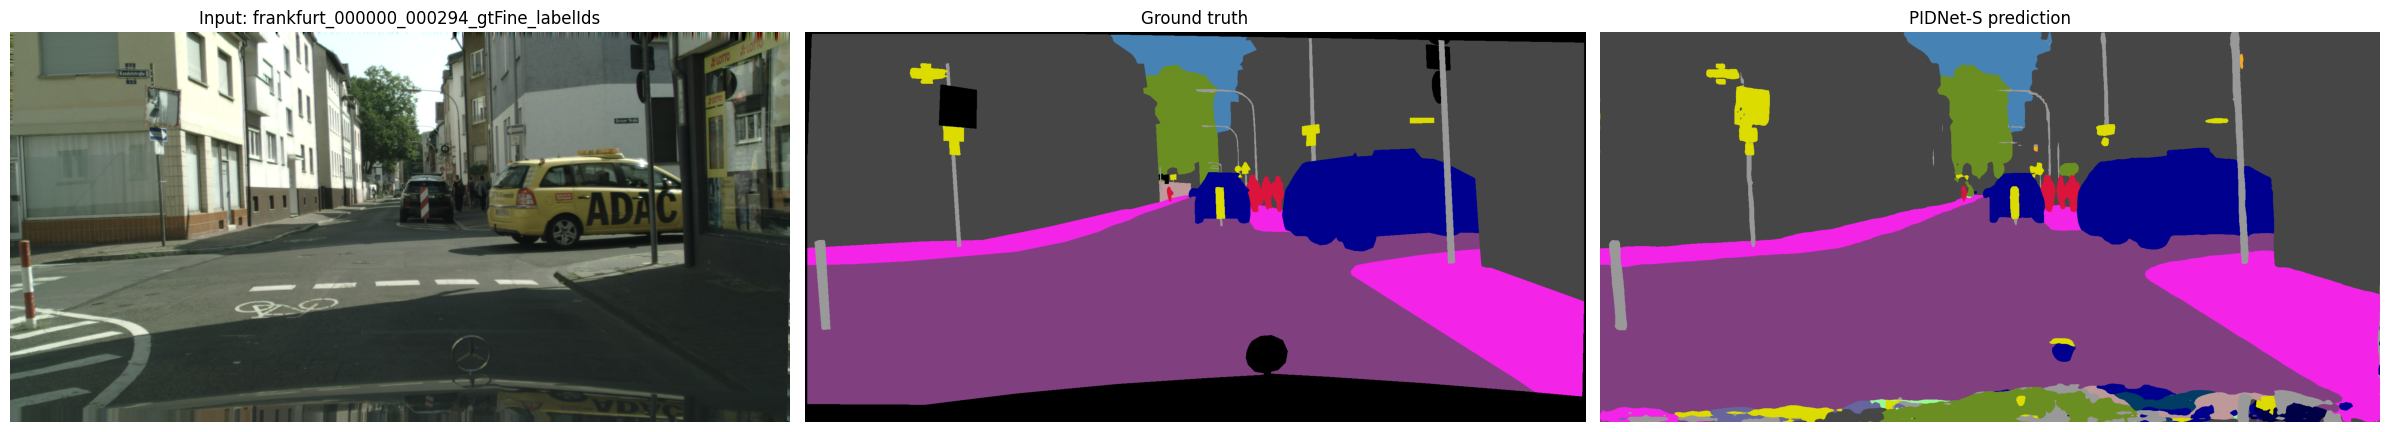

In [24]:
import matplotlib.pyplot as plt

best_path = os.path.join(config.OUTPUT_DIR, 'best.pt')
state = torch.load(best_path, map_location='cpu', weights_only=False)
state = state.get('state_dict', state)

eval_net = unwrap_model(model).model
eval_net.load_state_dict({k: v for k, v in state.items() if k in eval_net.state_dict()}, strict=False)
eval_net.eval()

item = test_dataset.files[0]
bgr = cv2.imread(os.path.join(test_dataset.image_root, item['img']), cv2.IMREAD_COLOR)
rgb_image = bgr[:, :, ::-1].copy()
gt = cv2.imread(os.path.join(test_dataset.gt_root, item['label']), cv2.IMREAD_GRAYSCALE)
gt = test_dataset.convert_label(gt)

input_tensor = torch.from_numpy(
    test_dataset.input_transform(bgr).transpose((2, 0, 1)).copy()
).unsqueeze(0).float().to(device)

with torch.no_grad(), torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
    prediction = eval_net(input_tensor)[config.TEST.OUTPUT_INDEX]
    prediction = F.interpolate(prediction.float(), size=rgb_image.shape[:2], mode='bilinear',
                               align_corners=config.MODEL.ALIGN_CORNERS)
    prediction = prediction.argmax(dim=1)[0].cpu().numpy()

fig, axes = plt.subplots(1, 3, figsize=(24, 5))
axes[0].imshow(rgb_image); axes[0].set_title(f"Input: {item['name']}")
axes[1].imshow(test_dataset.label2color(gt)); axes[1].set_title('Ground truth')
axes[2].imshow(test_dataset.label2color(prediction)); axes[2].set_title('PIDNet-S prediction')
for axis in axes:
    axis.axis('off')
plt.tight_layout()
plt.show()

#### Final evaluation on the validation set (Cityscapes test labels are not public)

In [25]:
class_names = ['road', 'sidewalk', 'building', 'wall', 'fence', 'pole', 'traffic light',
               'traffic sign', 'vegetation', 'terrain', 'sky', 'person', 'rider', 'car',
               'truck', 'bus', 'train', 'motorcycle', 'bicycle']
num_classes = config.DATASET.NUM_CLASSES
ignore_label = config.TRAIN.IGNORE_LABEL
confusion = np.zeros((num_classes, num_classes), dtype=np.float64)

with torch.no_grad():
    for images, labels, _, _, _ in testloader:
        images = images.to(device, non_blocking=use_cuda)
        labels = labels.long().to(device, non_blocking=use_cuda)
        with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
            predictions = eval_net(images)[config.TEST.OUTPUT_INDEX]
        predictions = F.interpolate(predictions.float(), size=labels.shape[-2:], mode='bilinear',
                                    align_corners=config.MODEL.ALIGN_CORNERS)
        confusion += get_confusion_matrix(labels, predictions, num_classes, ignore_label)

tp = np.diag(confusion)
fp = confusion.sum(axis=0) - tp
fn = confusion.sum(axis=1) - tp
denominator = tp + fp + fn
iou_per_class = np.divide(tp, denominator, out=np.full_like(tp, np.nan), where=denominator > 0)

print(f'Val mIoU: {np.nanmean(iou_per_class):.4f}')
print(f'Val pixel accuracy: {tp.sum() / confusion.sum():.4f}')
for idx, class_iou in enumerate(iou_per_class):
    print(f'  {idx:2d} {class_names[idx]:14s} IoU: {class_iou:.4f}')

Val mIoU: 0.7765
Val pixel accuracy: 0.9604
   0 road           IoU: 0.9822
   1 sidewalk       IoU: 0.8542
   2 building       IoU: 0.9245
   3 wall           IoU: 0.4814
   4 fence          IoU: 0.6046
   5 pole           IoU: 0.6517
   6 traffic light  IoU: 0.7156
   7 traffic sign   IoU: 0.7866
   8 vegetation     IoU: 0.9214
   9 terrain        IoU: 0.6297
  10 sky            IoU: 0.9468
  11 person         IoU: 0.8176
  12 rider          IoU: 0.6257
  13 car            IoU: 0.9502
  14 truck          IoU: 0.7966
  15 bus            IoU: 0.8778
  16 train          IoU: 0.7935
  17 motorcycle     IoU: 0.6209
  18 bicycle        IoU: 0.7719


In [26]:
def evaluate(loader, split_name):
    confusion = np.zeros((num_classes, num_classes), dtype=np.float64)

    with torch.no_grad():
        for images, labels, _, _, _ in loader:
            images = images.to(device, non_blocking=use_cuda)
            labels = labels.long().to(device, non_blocking=use_cuda)
            with torch.autocast(device_type='cuda', dtype=torch.float16, enabled=use_amp):
                predictions = eval_net(images)[config.TEST.OUTPUT_INDEX]
            predictions = F.interpolate(predictions.float(), size=labels.shape[-2:], mode='bilinear',
                                        align_corners=config.MODEL.ALIGN_CORNERS)
            confusion += get_confusion_matrix(labels, predictions, num_classes, ignore_label)

    tp = np.diag(confusion)
    fp = confusion.sum(axis=0) - tp
    fn = confusion.sum(axis=1) - tp
    denominator = tp + fp + fn
    iou_per_class = np.divide(tp, denominator, out=np.full_like(tp, np.nan), where=denominator > 0)

    print(f'{split_name} mIoU: {np.nanmean(iou_per_class):.4f}')
    print(f'{split_name} pixel accuracy: {tp.sum() / confusion.sum():.4f}')
    for idx, class_iou in enumerate(iou_per_class):
        print(f'  {idx:2d} {class_names[idx]:14s} IoU: {class_iou:.4f}')

    return iou_per_class, confusion


class_names = ['road', 'sidewalk', 'building', 'wall', 'fence', 'pole', 'traffic light',
               'traffic sign', 'vegetation', 'terrain', 'sky', 'person', 'rider', 'car',
               'truck', 'bus', 'train', 'motorcycle', 'bicycle']
num_classes = config.DATASET.NUM_CLASSES
ignore_label = config.TRAIN.IGNORE_LABEL

val_iou, val_confusion = evaluate(valloader, 'Val')
test_iou, test_confusion = evaluate(testloader, 'Test')

NameError: name 'valloader' is not defined